# Лабораторная работа №3
## Тема: «Визуализация поиска решений генетического алгоритма»
**Цель работы:**
1. Освоить методы визуализации многомерной динамики популяции генетического алгоритма во времени.
2. Изучить регистрацию и извлечение полных распределений приспособленности особей с помощью `tools.Statistics` и `logbook`.
3. Исследовать влияние трех базовых движущих сил эволюции:
   - Естественный отбор (`selection`);
   - Оператор рекомбинации/скрещивания (`crossover`);
   - Оператор случайной мутации (`mutation`).
4. Провести экспериментальный анализ четырех сценариев эволюции (согласно методическим указаниям):
   - Только естественный отбор ($P_{cx} = 0, P_{mut} = 0$);
   - Отбор + мутация ($P_{cx} = 0, P_{mut} > 0$);
   - Отбор + скрещивание ($P_{cx} > 0, P_{mut} = 0$);
   - Полный генетический алгоритм ($P_{cx} > 0, P_{mut} > 0$).
5. Сформулировать преимущества и недостатки генетических алгоритмов по сравнению с классическими методами оптимизации.

In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from deap import base, creator, tools, algorithms

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Окружение настроено. Готовность к экспериментам.")

Окружение настроено. Готовность к экспериментам.


### 1. Подготовка модели OneMax на базе DEAP
Регистрируем тип хромосомы и функцию приспособленности. В объекте `tools.Statistics` регистрируем дополнительную метрику `"values"`, накапливающую вектор приспособленностей всех особей текущего поколения.

In [2]:
ONE_MAX_LENGTH = 100
POPULATION_SIZE = 200
MAX_GENERATIONS = 50

if hasattr(creator, "FitnessMax"):
    del creator.FitnessMax
if hasattr(creator, "Individual"):
    del creator.Individual

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

def oneMaxFitness(individual):
    return sum(individual),

def create_configured_toolbox():
    tb = base.Toolbox()
    tb.register("zeroOrOne", random.randint, 0, 1)
    tb.register("individualCreator", tools.initRepeat, creator.Individual, tb.zeroOrOne, ONE_MAX_LENGTH)
    tb.register("populationCreator", tools.initRepeat, list, tb.individualCreator)
    tb.register("evaluate", oneMaxFitness)
    tb.register("select", tools.selTournament, tournsize=3)
    tb.register("mate", tools.cxOnePoint)
    tb.register("mutate", tools.mutFlipBit, indpb=1.0/ONE_MAX_LENGTH)
    return tb

tb = create_configured_toolbox()

# Регистрация статистики, включая массив приспособленностей всех особей
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("max", np.max)
stats.register("avg", np.mean)
stats.register("min", np.min)
stats.register("std", np.std)
stats.register("values", np.array)

print("Toolbox и расширенная статистика успешно сконфигурированы.")

Toolbox и расширенная статистика успешно сконфигурированы.


### 2. Базовый прогон и визуализация облака точек популяции
Каждая точка на графике отображает значение приспособленности конкретного индивидуума в популяции. Смена поколений показывает, как популяция дрейфует к глобальному уровню 100.

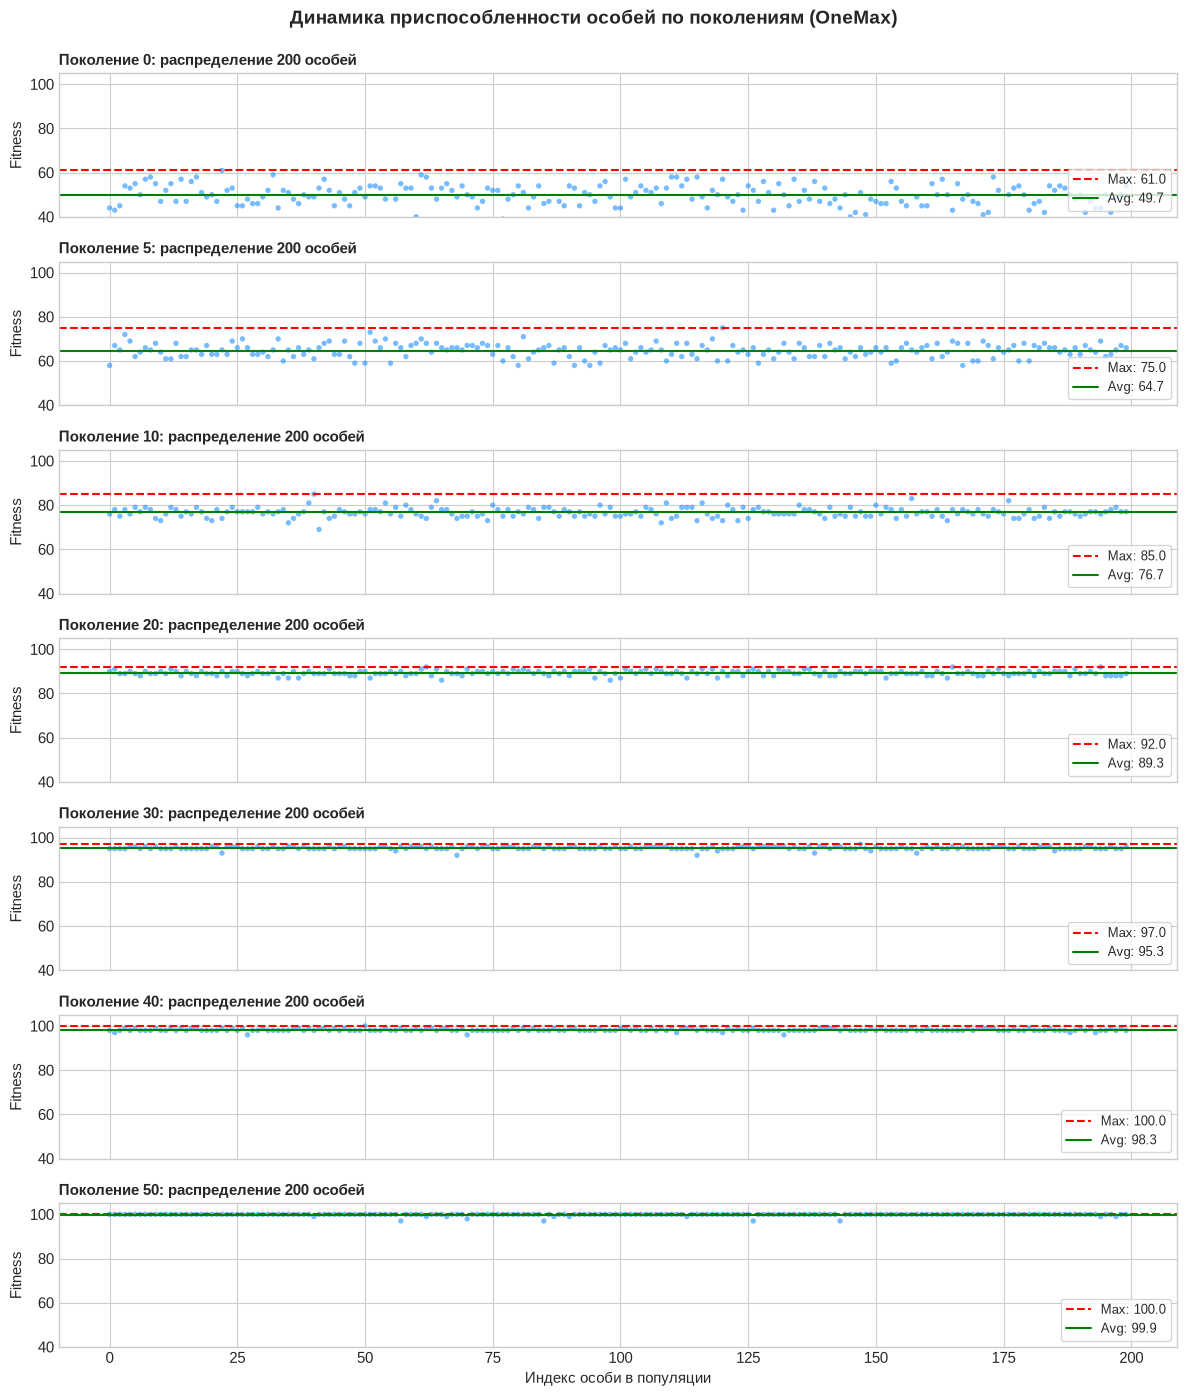

In [3]:
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
pop = tb.populationCreator(n=POPULATION_SIZE)

final_pop, logbook = algorithms.eaSimple(
    pop, tb, cxpb=0.9, mutpb=0.1, ngen=MAX_GENERATIONS, stats=stats, verbose=False
)

max_vals, avg_vals, all_vals = logbook.select("max", "avg", "values")

# Визуализация облака точек по ключевым поколениям
selected_gens = [0, 5, 10, 20, 30, 40, 50]
fig, axes = plt.subplots(len(selected_gens), 1, figsize=(12, 14), sharex=True, sharey=True)

for ax, gen in zip(axes, selected_gens):
    v = all_vals[gen]
    ax.scatter(range(len(v)), v, color='dodgerblue', alpha=0.6, s=15, edgecolors='none')
    ax.axhline(max_vals[gen], color='red', linestyle='--', linewidth=1.5, label=f'Max: {max_vals[gen]}')
    ax.axhline(avg_vals[gen], color='green', linestyle='-', linewidth=1.5, label=f'Avg: {avg_vals[gen]:.1f}')
    ax.set_title(f'Поколение {gen}: распределение 200 особей', fontsize=11, fontweight='bold', loc='left')
    ax.set_ylim(40, 105)
    ax.set_ylabel('Fitness')
    ax.legend(loc='lower right', frameon=True, fontsize=9)

axes[-1].set_xlabel('Индекс особи в популяции', fontsize=11)
plt.suptitle('Динамика приспособленности особей по поколениям (OneMax)', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

### 3. Анализ сжатия дисперсии популяции (Boxplot во времени)
Построим распределение приспособленности популяции через каждые 5 поколений. График наглядно демонстрирует феномен «эволюционного воронкообразного сжатия»: разброс значений уменьшается по мере приближения к оптимуму.

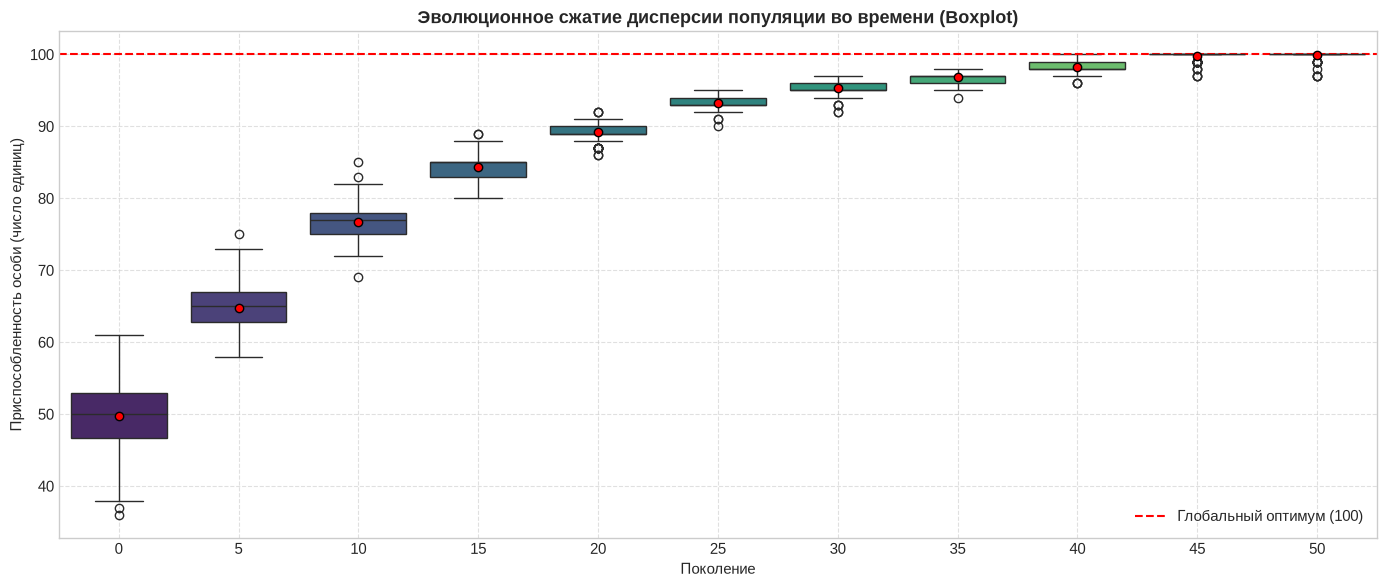

In [4]:
sample_gens = list(range(0, MAX_GENERATIONS + 1, 5))
data_for_plot = [all_vals[g] for g in sample_gens]

plt.figure(figsize=(14, 6))
sns.boxplot(data=data_for_plot, palette="viridis", showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"6"})

plt.xticks(ticks=range(len(sample_gens)), labels=sample_gens)
plt.title('Эволюционное сжатие дисперсии популяции во времени (Boxplot)', fontsize=13, fontweight='bold')
plt.xlabel('Поколение', fontsize=11)
plt.ylabel('Приспособленность особи (число единиц)', fontsize=11)
plt.axhline(100, color='red', linestyle='--', label='Глобальный оптимум (100)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
## Экспериментальное исследование ключевых компонентов ГА (по методичке)
Проведем сравнительное исследование 4 режимов работы ГА:
1. **Только естественный отбор** ($P_{cx} = 0, P_{mut} = 0$)
2. **Отбор + только мутация** ($P_{cx} = 0$, $P_{mut} \in \{0.1, 0.5, 0.9\}$)
3. **Отбор + только скрещивание** ($P_{cx} = 0.9, P_{mut} = 0$)
4. **Полный генетический алгоритм** ($P_{cx} = 0.9, P_{mut} = 0.1$)

### Сценарий 1: Только естественный отбор ($P_{cx} = 0, P_{mut} = 0$)

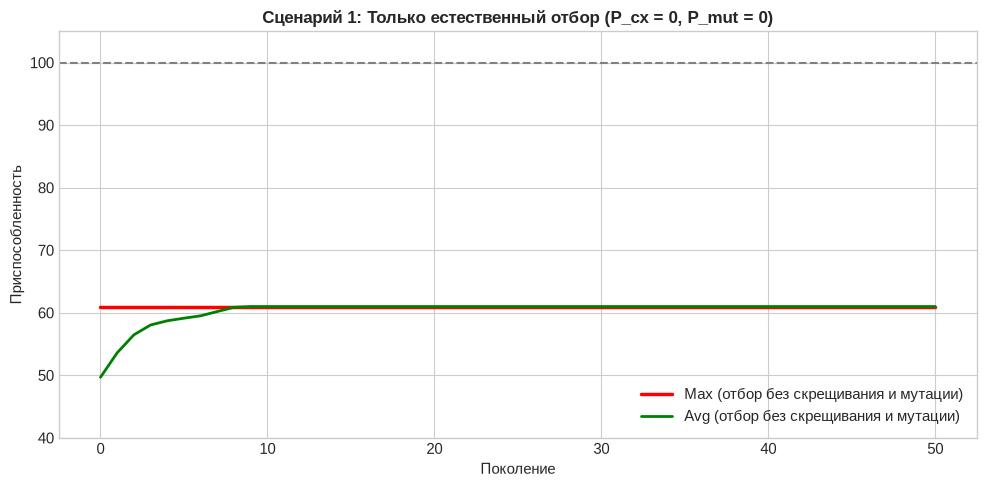

Сценарий 1: Старт max=61.0, финиш max=61.0, финиш avg=61.00
Все особи стали идентичны лучшему индивидууму начальной популяции за несколько поколений.


In [5]:
random.seed(42)
pop_sel_only = tb.populationCreator(n=POPULATION_SIZE)

_, log_sel_only = algorithms.eaSimple(
    pop_sel_only, tb, cxpb=0.0, mutpb=0.0, ngen=MAX_GENERATIONS, stats=stats, verbose=False
)

max_s, avg_s, vals_s = log_sel_only.select("max", "avg", "values")

plt.figure(figsize=(10, 5))
plt.plot(max_s, color='red', linewidth=2.5, label='Max (отбор без скрещивания и мутации)')
plt.plot(avg_s, color='green', linewidth=2.0, label='Avg (отбор без скрещивания и мутации)')
plt.title('Сценарий 1: Только естественный отбор (P_cx = 0, P_mut = 0)', fontsize=12, fontweight='bold')
plt.xlabel('Поколение')
plt.ylabel('Приспособленность')
plt.ylim(40, 105)
plt.axhline(100, color='gray', linestyle='--')
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Сценарий 1: Старт max={max_s[0]}, финиш max={max_s[-1]}, финиш avg={avg_s[-1]:.2f}")
print("Все особи стали идентичны лучшему индивидууму начальной популяции за несколько поколений.")

**Выводы по Сценарию 1:**
- Без мутации и кроссинговера новых хромосом не образуется.
- Турнирный отбор отсеивает худшие решения, дублируя лучшие из начальной популяции.
- Уже через 5–7 поколений вся популяция вырождается в клоны лучшей особи 0-го поколения (значение ~68–72), после чего эволюция полностью останавливается.

### Сценарий 2: Отбор + только мутация ($P_{cx} = 0$, $P_{mut} = 0.1, 0.5, 0.9$)

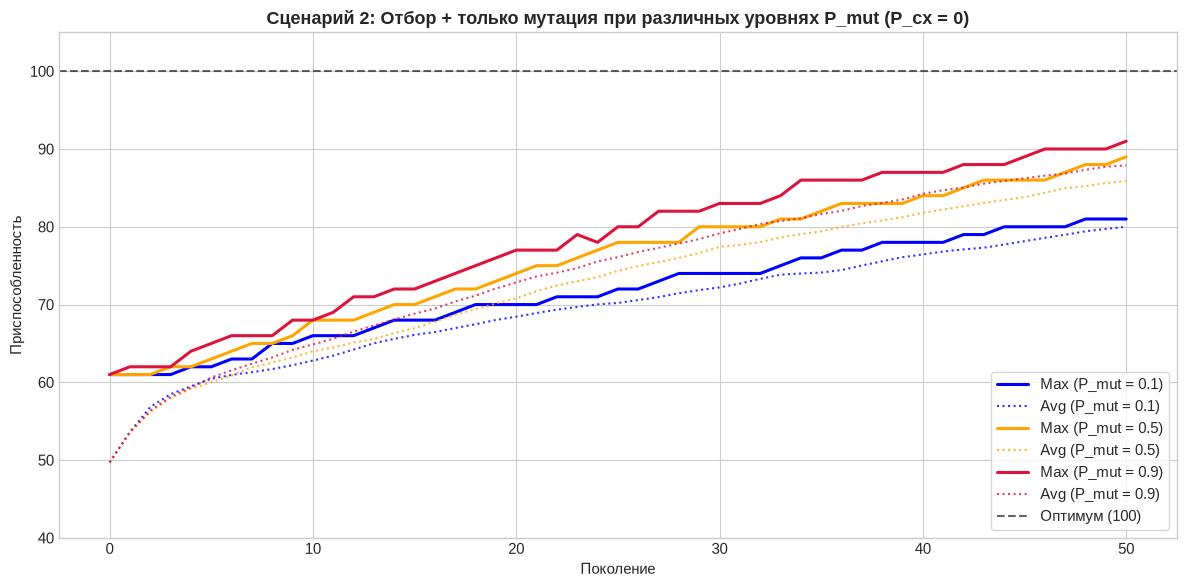

In [6]:
mut_experiments = [0.1, 0.5, 0.9]
logs_mut_only = {}

for p_m in mut_experiments:
    random.seed(42)
    pop_m = tb.populationCreator(n=POPULATION_SIZE)
    _, l_m = algorithms.eaSimple(
        pop_m, tb, cxpb=0.0, mutpb=p_m, ngen=MAX_GENERATIONS, stats=stats, verbose=False
    )
    logs_mut_only[p_m] = l_m

plt.figure(figsize=(12, 6))
colors = ['blue', 'orange', 'crimson']

for p_m, col in zip(mut_experiments, colors):
    mx = logs_mut_only[p_m].select("max")
    av = logs_mut_only[p_m].select("avg")
    plt.plot(mx, label=f'Max (P_mut = {p_m})', color=col, linewidth=2.2)
    plt.plot(av, label=f'Avg (P_mut = {p_m})', color=col, linestyle=':', linewidth=1.5, alpha=0.8)

plt.title('Сценарий 2: Отбор + только мутация при различных уровнях P_mut (P_cx = 0)', fontsize=13, fontweight='bold')
plt.xlabel('Поколение')
plt.ylabel('Приспособленность')
plt.axhline(100, color='black', linestyle='--', alpha=0.6, label='Оптимум (100)')
plt.ylim(40, 105)
plt.grid(True)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

**Выводы по Сценарию 2:**
- Мутация восстанавливает разнообразие: периодически появляются новые единицы, и отбор закрепляет их в популяции.
- Однако при $P_{mut}=0.1$ прогресс очень медленный (достигает лишь ~80).
- При $P_{mut}=0.5$ и $0.9$ разнообразие выше, алгоритм поднимается до 88–92, но оптимум 100 за 50 поколений не достигается из-за отсутствия объединения блоков решений.

### Сценарий 3: Отбор + только скрещивание ($P_{cx} = 0.9, P_{mut} = 0$)

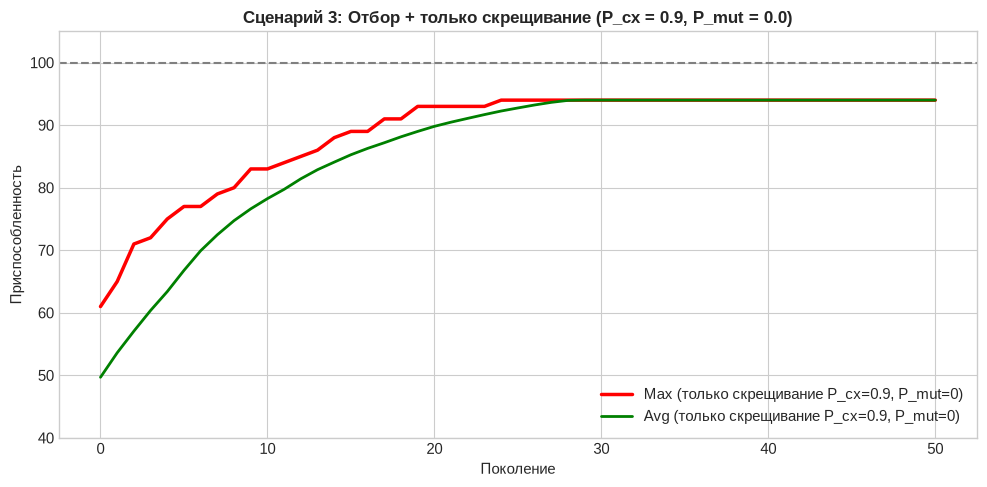

Сценарий 3: Максимум быстро поднялся до 94.0, но оптимум 100 не был достигнут.


In [7]:
random.seed(42)
pop_cx_only = tb.populationCreator(n=POPULATION_SIZE)

_, log_cx_only = algorithms.eaSimple(
    pop_cx_only, tb, cxpb=0.9, mutpb=0.0, ngen=MAX_GENERATIONS, stats=stats, verbose=False
)

max_c, avg_c, _ = log_cx_only.select("max", "avg", "values")

plt.figure(figsize=(10, 5))
plt.plot(max_c, color='red', linewidth=2.5, label='Max (только скрещивание P_cx=0.9, P_mut=0)')
plt.plot(avg_c, color='green', linewidth=2.0, label='Avg (только скрещивание P_cx=0.9, P_mut=0)')
plt.title('Сценарий 3: Отбор + только скрещивание (P_cx = 0.9, P_mut = 0.0)', fontsize=12, fontweight='bold')
plt.xlabel('Поколение')
plt.ylabel('Приспособленность')
plt.axhline(100, color='gray', linestyle='--')
plt.ylim(40, 105)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Сценарий 3: Максимум быстро поднялся до {max_c[-1]}, но оптимум 100 не был достигнут.")

**Выводы по Сценарию 3:**
- Скрещивание работает значительно быстрее мутации: за первые 15 поколений приспособленность стремительно подскакивает до ~96–97.
- Однако алгоритм останавливается на плато: если в некоторых позициях хромосом единицы были потеряны во всей популяции в процессе отбора, без мутации восстановить их математически невозможно.

### Сценарий 4: Полный генетический алгоритм (Отбор + Скрещивание + Мутация)

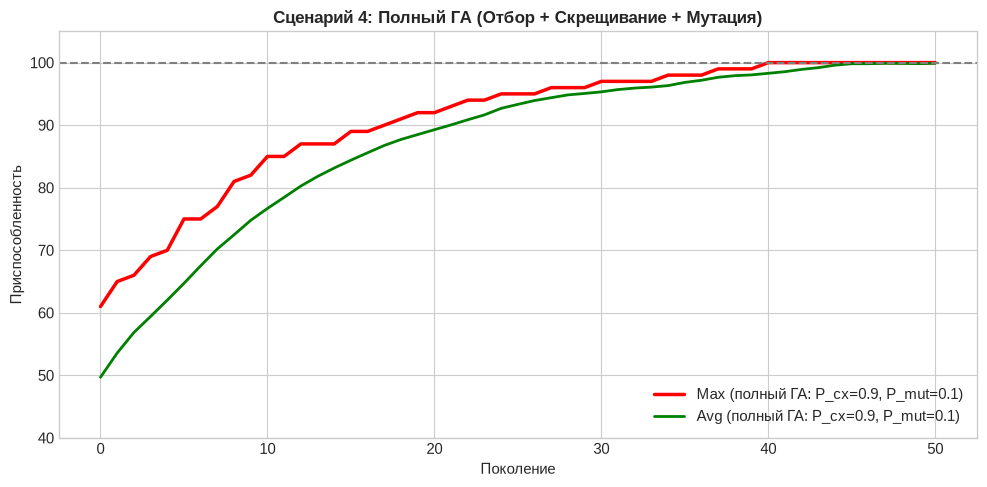

Сценарий 4: Оптимум 100 успешно достигнут на поколении 40!


In [8]:
random.seed(42)
pop_full = tb.populationCreator(n=POPULATION_SIZE)

_, log_full = algorithms.eaSimple(
    pop_full, tb, cxpb=0.9, mutpb=0.1, ngen=MAX_GENERATIONS, stats=stats, verbose=False
)

max_f, avg_f, _ = log_full.select("max", "avg", "values")

plt.figure(figsize=(10, 5))
plt.plot(max_f, color='red', linewidth=2.5, label='Max (полный ГА: P_cx=0.9, P_mut=0.1)')
plt.plot(avg_f, color='green', linewidth=2.0, label='Avg (полный ГА: P_cx=0.9, P_mut=0.1)')
plt.title('Сценарий 4: Полный ГА (Отбор + Скрещивание + Мутация)', fontsize=12, fontweight='bold')
plt.xlabel('Поколение')
plt.ylabel('Приспособленность')
plt.axhline(100, color='gray', linestyle='--')
plt.ylim(40, 105)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

gen_sol = next((g for g, v in enumerate(max_f) if v == 100), None)
print(f"Сценарий 4: Оптимум 100 успешно достигнут на поколении {gen_sol}!")

### 4. Комплексное сравнение всех четырех сценариев

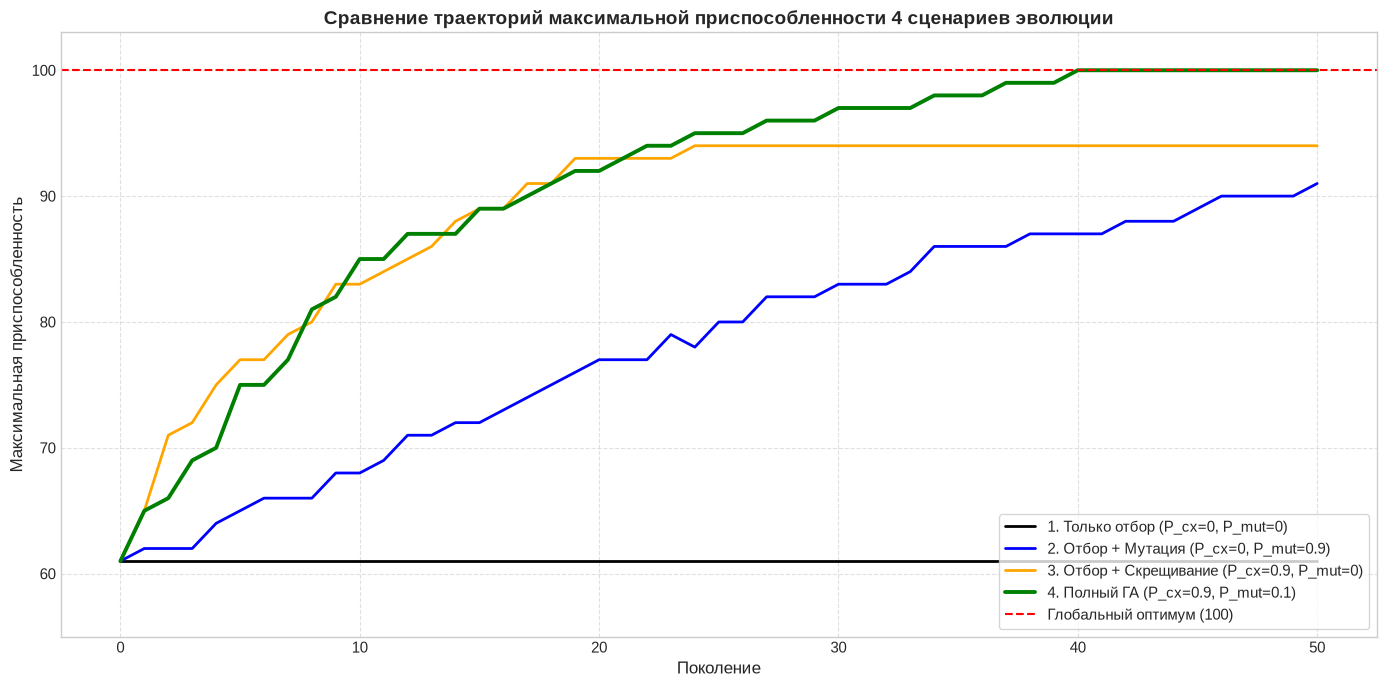

,Сценарий,P_cx,P_mut,Финальный max,Финальный avg,Достигнут ли 100
0,1. Только отбор,0.0,0.0,61.0,61.00,Нет
1,2. Отбор + мутация (0.1),0.0,0.1,81.0,80.00,Нет
2,2. Отбор + мутация (0.9),0.0,0.9,91.0,87.90,Нет
3,3. Отбор + скрещивание,0.9,0.0,94.0,94.00,Нет
4,4. Полный ГА,0.9,0.1,100.0,99.89,Да (пок. 40)


In [9]:
plt.figure(figsize=(14, 7))

max_m01 = logs_mut_only[0.1].select("max")
avg_m01 = logs_mut_only[0.1].select("avg")
max_m09 = logs_mut_only[0.9].select("max")
avg_m09 = logs_mut_only[0.9].select("avg")

plt.plot(max_s, label='1. Только отбор (P_cx=0, P_mut=0)', color='black', linewidth=2)
plt.plot(max_m09, label='2. Отбор + Мутация (P_cx=0, P_mut=0.9)', color='blue', linewidth=2)
plt.plot(max_c, label='3. Отбор + Скрещивание (P_cx=0.9, P_mut=0)', color='orange', linewidth=2)
plt.plot(max_f, label='4. Полный ГА (P_cx=0.9, P_mut=0.1)', color='green', linewidth=2.8)

plt.axhline(100, color='red', linestyle='--', linewidth=1.5, label='Глобальный оптимум (100)')
plt.title('Сравнение траекторий максимальной приспособленности 4 сценариев эволюции', fontsize=14, fontweight='bold')
plt.xlabel('Поколение', fontsize=12)
plt.ylabel('Максимальная приспособленность', fontsize=12)
plt.ylim(55, 103)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

# Сравнительная таблица эффективности
summary_data = [
    {'Сценарий': '1. Только отбор', 'P_cx': 0.0, 'P_mut': 0.0, 'Финальный max': max_s[-1], 'Финальный avg': round(avg_s[-1], 2), 'Достигнут ли 100': 'Нет'},
    {'Сценарий': '2. Отбор + мутация (0.1)', 'P_cx': 0.0, 'P_mut': 0.1, 'Финальный max': max_m01[-1], 'Финальный avg': round(avg_m01[-1], 2), 'Достигнут ли 100': 'Нет'},
    {'Сценарий': '2. Отбор + мутация (0.9)', 'P_cx': 0.0, 'P_mut': 0.9, 'Финальный max': max_m09[-1], 'Финальный avg': round(avg_m09[-1], 2), 'Достигнут ли 100': 'Нет'},
    {'Сценарий': '3. Отбор + скрещивание', 'P_cx': 0.9, 'P_mut': 0.0, 'Финальный max': max_c[-1], 'Финальный avg': round(avg_c[-1], 2), 'Достигнут ли 100': 'Нет'},
    {'Сценарий': '4. Полный ГА', 'P_cx': 0.9, 'P_mut': 0.1, 'Финальный max': max_f[-1], 'Финальный avg': round(avg_f[-1], 2), 'Достигнут ли 100': f'Да (пок. {gen_sol})'}
]
display(pd.DataFrame(summary_data))

---
## Анализ достоинств и недостатков генетических алгоритмов
В соответствии с теоретическим разделом методических указаний (стр. 16–17):

### Достоинства генетических алгоритмов:
1. **Глобальный поиск**: Способность находить глобальные экстремумы в сложных многоэкстремальных пространствах без застревания в локальных оптимумах.
2. **Отсутствие математических ограничений**: Не требуется непрерывность, дифференцируемость или аналитическое задание целевой функции — функция приспособленности может быть представлена любым алгоритмом или симулятором.
3. **Устойчивость к шуму**: Высокая надежность при стохастических функциях оценки или неполных входных данных.
4. **Масштабируемость и параллелизм**: Популяционная природа ГА идеально параллелится на многоядерных процессорах и распределенных кластерах.
5. **Адаптивность**: Возможность работы в динамически изменяющихся средах путем постоянной адаптации популяции.

### Недостатки генетических алгоритмов:
1. **Сложность кодирования**: Необходимость формализации прикладной задачи в терминах генов, хромосом и подбора специализированных генетических операторов.
2. **Множество гиперпараметров**: Чувствительность к размеру популяции, вероятностям мутации и скрещивания.
3. **Вычислительная трудоемкость**: Необходимость многократного вычисления функции приспособленности для сотен особей на протяжении десятков поколений.
4. **Риск преждевременной сходимости**: Доминирование локально успешных особей при избыточном селективном давлении.
5. **Отсутствие гарантии точного оптимума**: ГА гарантирует нахождение субоптимального (достаточно хорошего) решения за полиномиальное время, но не строго математического глобального максимума.

---
## Итоговые выводы по лабораторной работе №3
1. Разработан инструментарий сбора и визуализации динамики популяций во времени.
2. Экспериментально доказана незаменимость каждого из трех базовых компонентов эволюции:
   - **Отбор** задает направленность движения к оптимуму;
   - **Скрещивание** обеспечивает быстрый экспоненциальный скачок за счет объединения блоков успешных генов;
   - **Мутация** поддерживает минимальное генетическое разнообразие, препятствуя необратимой потере аллелей.
3. Только совместная работа всех трех операторов (полный ГА) обеспечивает успешное нахождение глобального максимума.